# DSMarket — ¿Cuánto responde la demanda al precio?

**De:** Nicole, Data Science
**Para:** Michelle (Chief Digital Officer), Joelle (Marketing)

Michelle planteó al principio del proyecto que *"nuestras acciones de marketing tendrían que explotar esas diferencias de precio"*. En el EDA respondimos la parte descriptiva: hay dispersión de precios entre tiendas, y es mayor en SUPERMARKET de lo que uno esperaría. Pero nunca respondimos la pregunta que de verdad importa para decidir una promoción: **si bajamos el precio un 10%, ¿cuánto más vendemos?**

Este notebook intenta responderla. El resultado no es el que esperábamos, y la conclusión honesta es más útil que el número que podríamos haber reportado.

## 1. Configuración

In [1]:
import os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sys.path.insert(0, os.path.join('lakehouse', 'scripts'))
from pipeline import conectar

DSMARKET_NAVY = "#0a2a5c"; DSMARKET_BLUE = "#2a78d6"
DSMARKET_GOLD = "#eda100"; DSMARKET_GREEN = "#6a9f1f"
sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "grid.color": "#e1e0d9",
    "figure.facecolor": "white", "axes.facecolor": "white"})
plt.rcParams["axes.titlecolor"] = DSMARKET_NAVY
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option('display.width', 200)
%matplotlib inline

## 2. Qué es la elasticidad y por qué no alcanza con correlacionar

La **elasticidad precio de la demanda** es el porcentaje en que cambia la cantidad vendida cuando el precio cambia un 1%. Si vale −0,5, subir el precio un 10% hace caer el volumen un 5%. Por debajo de −1 la demanda es *elástica* (bajar el precio aumenta la facturación); por encima, *inelástica* (bajar el precio la reduce).

El problema es que **no se puede estimar comparando productos caros con productos baratos**. Los productos caros se venden menos que los baratos, pero no *porque* sean caros: son cosas distintas, compradas por motivos distintos. Y tampoco se puede comparar semanas caras con semanas baratas de un mismo producto sin más, porque el precio no baja al azar — baja cuando el negocio decide una promoción, que suele coincidir con momentos de demanda alta o baja por otros motivos.

La estrategia estándar para aislar el efecto es un **panel con efectos fijos en dos vías**:

$$\log q_{ist} = \beta \log p_{ist} + \alpha_{is} + \gamma_t + \varepsilon_{ist}$$

donde $\alpha_{is}$ absorbe todo lo permanente de ese producto en esa tienda (su popularidad, su sitio en la góndola) y $\gamma_t$ absorbe lo que pasa en toda la cadena esa semana (estacionalidad, festivos, clima). Lo que queda para identificar $\beta$ son las desviaciones del precio respecto de su propia media, comparadas en el mismo momento del tiempo.

Con 30.490 series no se pueden crear 30.490 variables ficticias. Se usa el teorema de **Frisch-Waugh-Lovell**: en vez de estimar los efectos fijos, se *proyectan fuera* restando iterativamente las medias de cada grupo hasta converger. El coeficiente resultante es idéntico y el cálculo cabe en memoria.

In [2]:
def desmediar(v, grupos, iteraciones=30, tol=1e-10):
    """Proyecta v fuera del espacio de los efectos fijos (proyecciones alternadas)."""
    v = v.astype(np.float64).copy()
    for _ in range(iteraciones):
        maximo = 0.0
        for g, n_g in grupos:
            medias = (np.bincount(g, weights=v, minlength=n_g) /
                      np.maximum(np.bincount(g, minlength=n_g), 1e-12))
            ajuste = medias[g]
            maximo = max(maximo, np.abs(ajuste).max())
            v -= ajuste
        if maximo < tol:
            break
    return v

def regresion(df, col_y, col_x, etiqueta):
    """OLS con efectos fijos absorbidos y errores estándar agrupados por serie."""
    d = df[df[col_y].notna() & df[col_x].notna()]
    y, x = d[col_y].to_numpy(np.float64), d[col_x].to_numpy(np.float64)
    grupos = [(d['serie'].to_numpy(), int(d['serie'].max()) + 1),
              (d['sem'].to_numpy(), int(d['sem'].max()) + 1)]
    yt, xt = desmediar(y, grupos), desmediar(x, grupos)
    beta = float((xt @ yt) / (xt @ xt))
    resid = yt - beta * xt
    g, n_g = grupos[0]
    suma = np.bincount(g, weights=xt * resid, minlength=n_g)
    bread = 1.0 / float(xt @ xt)
    se = float(np.sqrt(bread * (suma ** 2).sum() * bread))
    return {'especificación': etiqueta, 'elasticidad': beta, 'error_estándar': se,
            'estadístico_t': beta / se if se > 0 else np.nan, 'n_obs': len(y)}

In [3]:
# Una sola consulta trae todo lo que necesitan las cinco especificaciones: niveles, rezagos,
# adelantos y primeras diferencias. Cargar el panel una sola vez es obligatorio — son 6,6
# millones de filas y el equipo de desarrollo tenía 3,8 GB de memoria.
con = conectar()
panel = con.execute("""
    WITH dias AS (
        SELECT fecha, CAST(floor((row_number() OVER (ORDER BY fecha) - 1) / 7) AS INTEGER) AS sem
        FROM dim_calendario
    ),
    p AS (
        SELECT dense_rank() OVER (ORDER BY v.item, v.store_code) - 1 AS serie,
               v.item, d.sem, sum(v.unidades) AS q, avg(v.precio) AS p
        FROM fact_ventas v JOIN dias d USING (fecha)
        WHERE v.precio IS NOT NULL
        GROUP BY v.item, v.store_code, d.sem
    ),
    r AS (
        SELECT *, lag(sem) OVER w AS sem_ant, lag(p) OVER w AS p_ant, lag(q) OVER w AS q_ant,
                  lead(p) OVER w AS p_sig, lead(sem) OVER w AS sem_sig
        FROM p WINDOW w AS (PARTITION BY serie ORDER BY sem)
    )
    SELECT r.serie::INTEGER AS serie, r.sem::SMALLINT AS sem, pr.arquetipo, r.p::REAL AS p,
           CASE WHEN r.q > 0 THEN ln(r.q) END::REAL          AS log_q,
           ln(r.q + 1)::REAL                                  AS log_q1,
           ln(r.p)::REAL                                      AS log_p,
           ln(r.p_sig)::REAL                                  AS log_p_sig,
           ln(r.p_ant)::REAL                                  AS log_p_ant,
           CASE WHEN r.sem_ant = r.sem - 1 THEN (ln(r.q + 1) - ln(r.q_ant + 1))::REAL END AS dlog_q,
           CASE WHEN r.sem_ant = r.sem - 1 THEN (ln(r.p) - ln(r.p_ant))::REAL END          AS dlog_p,
           CASE WHEN r.sem_sig = r.sem + 1 THEN (ln(r.p_sig) - ln(r.p))::REAL END          AS dlog_p_fut
    FROM r JOIN dim_producto pr ON pr.item = r.item
""").df()
panel['arquetipo'] = panel['arquetipo'].astype('category')

variacion = con.execute("""
    WITH dias AS (SELECT fecha, CAST(floor((row_number() OVER (ORDER BY fecha)-1)/7) AS INTEGER) AS sem
                  FROM dim_calendario),
         p AS (SELECT item, store_code, sem, avg(precio) AS precio FROM fact_ventas v
               JOIN dias d USING (fecha) WHERE precio IS NOT NULL GROUP BY 1,2,3)
    SELECT round(avg(n),1) AS precios_distintos_por_serie,
           round(median(rango),1) AS rango_mediano_pct,
           sum(CASE WHEN n = 1 THEN 1 ELSE 0 END) AS series_sin_ninguna_variacion,
           count(*) AS series
    FROM (SELECT item, store_code, count(DISTINCT precio) AS n,
                 (max(precio)-min(precio))/nullif(avg(precio),0)*100 AS rango
          FROM p GROUP BY 1,2)
""").df()
con.close()
print(f"panel: {len(panel):,} observaciones  ({panel.memory_usage(deep=True).sum()/1e6:.0f} MB en memoria)")
print(f"con venta positiva: {panel['log_q'].notna().sum():,} ({panel['log_q'].notna().mean():.1%})")
print()
print("Variación de precio disponible para identificar el efecto:")
variacion

panel: 6,660,528 observaciones  (286 MB en memoria)
con venta positiva: 5,004,711 (75.1%)

Variación de precio disponible para identificar el efecto:


,precios_distintos_por_serie,rango_mediano_pct,series_sin_ninguna_variacion,series
0,2.7,8.5,8468.0,30490


## 3. Primer intento: el resultado que parecía bueno

Estimamos la especificación de niveles con efectos fijos de serie y de semana, sobre las observaciones con venta positiva, y dos variantes de robustez.

In [4]:
niveles = pd.DataFrame([
    regresion(panel, 'log_q', 'log_p',  'Principal: log-log, EF serie + semana'),
    regresion(panel, 'log_q1', 'log_p', 'Robustez: log(1+q), incluye los ceros'),
])
niveles.round(4)

,especificación,elasticidad,error_estándar,estadístico_t,n_obs
0,"Principal: log-log, EF serie + semana",-0.3953,0.0205,-19.2897,5004711
1,"Robustez: log(1+q), incluye los ceros",-0.4385,0.0345,-12.6933,6660528


In [5]:
por_arquetipo = pd.DataFrame([
    regresion(panel[panel['arquetipo'] == a], 'log_q', 'log_p', a)
    for a in sorted(panel['arquetipo'].dropna().unique())
]).rename(columns={'especificación': 'arquetipo'})
por_arquetipo['precio_medio'] = [panel.loc[panel['arquetipo'] == a, 'p'].mean()
                                 for a in por_arquetipo['arquetipo']]
por_arquetipo.round(4)

,arquetipo,elasticidad,error_estándar,estadístico_t,n_obs,precio_medio
0,"Precio alto, pocas unidades",-0.2572,0.0694,-3.7069,318176,17.0408
1,Alta rotación diaria,-0.6151,0.0493,-12.4751,1364465,2.6207
2,Rotación baja sin picos,-0.4421,0.0384,-11.5096,1197704,4.9845
3,Venta esporádica con pico en eventos,0.0954,0.0564,1.6927,433273,6.1921
4,Pico de fin de semana,-0.3962,0.0342,-11.5951,1551006,5.2822
5,Pico de diciembre,-0.1330,0.0811,-1.6407,140087,5.3839


**A primera vista, todo encaja.** La elasticidad global es **−0,40** con un estadístico t de −19: negativa, como manda la teoría, y muy significativa. Y el patrón por grupo de producto (Tarea 2) cuenta una historia perfectamente creíble:

- El grupo **Alta rotación diaria** (sobre todo alimentación) es el más sensible (−0,62): son los productos baratos (2,62 $ de media) y de compra frecuente, donde el cliente conoce el precio de memoria.
- El grupo **Precio alto, pocas unidades** (accesorios y hogar) es de los menos sensibles (−0,26) y los más caros (17,04 $ de media): quien compra un producto caro mira menos la etiqueta.
- Los grupos **Venta esporádica con pico en eventos** y **Pico de diciembre** no reaccionan (+0,10 y −0,13, sin significación): se compran por la fecha, no por el precio.

Es un resultado que se defiende solo, encaja con la intuición y daría para un capítulo entero de recomendaciones de precios. **El problema es que probablemente sea falso.**

## 4. La prueba que lo tira abajo

Antes de construir una recomendación de precios sobre este número, conviene someterlo a una prueba que puede refutarlo. La más directa es un **placebo temporal**: usar el precio de la semana *siguiente* para "explicar" las ventas de esta semana.

El precio futuro no puede causar las ventas de hoy. Si aun así aparece un efecto del mismo tamaño, significa que lo que estamos midiendo no es la reacción al precio, sino una correlación entre el nivel de precio de un período y su volumen — es decir, exactamente el sesgo que los efectos fijos debían eliminar.

In [6]:
pd.DataFrame([
    regresion(panel, 'log_q', 'log_p',     'Precio de ESTA semana (el efecto que buscamos)'),
    regresion(panel, 'log_q', 'log_p_sig', 'PLACEBO — precio de la semana SIGUIENTE'),
    regresion(panel, 'log_q', 'log_p_ant', 'Precio de la semana ANTERIOR'),
]).round(4)

,especificación,elasticidad,error_estándar,estadístico_t,n_obs
0,Precio de ESTA semana (el efecto que buscamos),-0.3953,0.0205,-19.2897,5004711
1,PLACEBO — precio de la semana SIGUIENTE,-0.3984,0.0200,-19.9347,4984978
2,Precio de la semana ANTERIOR,-0.4045,0.0211,-19.1745,4993780


**Hallazgo — la prueba falla, y falla de la peor manera posible:**

| Especificación | Elasticidad | t |
|---|---|---|
| Precio de esta semana (el efecto que buscamos) | −0,395 | −19,3 |
| **PLACEBO — precio de la semana SIGUIENTE** | **−0,398** | **−19,9** |
| Precio de la semana anterior | −0,405 | −19,2 |

**El precio de la semana que viene "explica" las ventas de esta semana exactamente igual de bien que el precio actual.** Como el futuro no puede causar el pasado, lo que estamos midiendo no es una respuesta al precio.

La causa es concreta y se ve en los datos: el precio de cada serie es **extremadamente persistente** — apenas 2,7 precios distintos a lo largo de 274 semanas, y 8.468 series (el 28%) nunca cambian de precio. Con esa persistencia, "el precio de esta semana", "el de la anterior" y "el de la siguiente" son prácticamente la misma variable, y los efectos fijos no alcanzan a separar el efecto del precio de la diferencia permanente entre períodos caros y baratos de cada producto.

Dicho de otra forma: el −0,40 no mide *qué pasa cuando bajamos el precio*, mide *que los períodos en que un producto está más caro coinciden con períodos en que se vende menos* — que puede deberse al precio, o a que se rebaja lo que no rota, o a cualquier otra cosa. **Si hubiéramos publicado ese número sin esta prueba, habríamos construido una recomendación de precios sobre una correlación espuria.**

## 5. Segundo intento: mirar solo los cambios de precio

Si el problema es que el nivel del precio arrastra información que no queremos, la solución es **diferenciar**: en vez de relacionar el nivel de ventas con el nivel de precio, relacionamos el *cambio* de ventas con el *cambio* de precio.

$$\Delta \log q_{ist} = \beta\, \Delta \log p_{ist} + \gamma_t + \varepsilon_{ist}$$

Diferenciar elimina por construcción todo lo permanente de la serie, incluida la parte que los efectos fijos no lograron limpiar. Ahora la identificación viene únicamente de las semanas en que el precio efectivamente se movió. Y volvemos a hacer el placebo, esta vez con el cambio *futuro* del precio.

In [7]:
dif = panel[panel['dlog_q'].notna() & panel['dlog_p'].notna()]
hubo_cambio = dif['dlog_p'].abs() > 1e-6
print(f"observaciones en diferencias:   {len(dif):,}")
print(f"con cambio de precio efectivo:  {hubo_cambio.sum():,} ({hubo_cambio.mean():.1%})")
print(f"magnitud mediana cuando cambia: {np.exp(dif.loc[hubo_cambio,'dlog_p'].abs().median())-1:.1%}")
print()
pd.DataFrame([
    regresion(dif, 'dlog_q', 'dlog_p', 'Δlog(q) ~ Δlog(p) — todas las semanas'),
    regresion(dif[hubo_cambio], 'dlog_q', 'dlog_p', 'Δlog(q) ~ Δlog(p) — solo semanas con cambio'),
    regresion(dif, 'dlog_q', 'dlog_p_fut', 'PLACEBO — cambio de precio de la semana siguiente'),
]).round(4)

observaciones en diferencias:   6,630,038
con cambio de precio efectivo:  75,602 (1.1%)
magnitud mediana cuando cambia: 10.1%



,especificación,elasticidad,error_estándar,estadístico_t,n_obs
0,Δlog(q) ~ Δlog(p) — todas las semanas,0.0205,0.0102,2.0121,6630038
1,Δlog(q) ~ Δlog(p) — solo semanas con cambio,0.0180,0.0103,1.7400,75602
2,PLACEBO — cambio de precio de la semana siguiente,0.0112,0.0094,1.1925,6599548


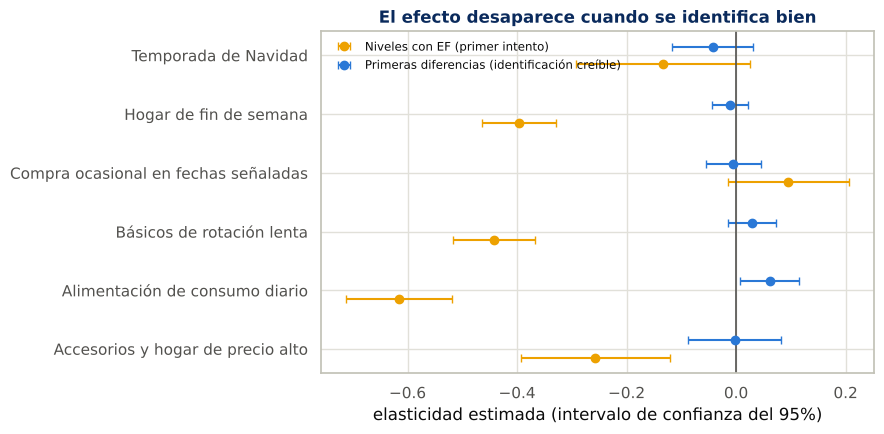

,arquetipo,elasticidad,error_estándar,estadístico_t,n_obs
0,"Precio alto, pocas unidades",-0.0028,0.0431,-0.0651,4554
1,Alta rotación diaria,0.0612,0.0271,2.2542,19784
2,Rotación baja sin picos,0.0287,0.0221,1.2996,18779
3,Venta esporádica con pico en eventos,-0.0048,0.0255,-0.1872,8357
4,Pico de fin de semana,-0.0110,0.0164,-0.6741,21888
5,Pico de diciembre,-0.0430,0.0378,-1.1359,2240


In [8]:
dc = dif[hubo_cambio]
arq_dif = pd.DataFrame([regresion(dc[dc['arquetipo'] == a], 'dlog_q', 'dlog_p', a)
                        for a in sorted(dc['arquetipo'].dropna().unique())]
                       ).rename(columns={'especificación': 'arquetipo'})

fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(arq_dif))
niv = por_arquetipo.set_index('arquetipo').loc[arq_dif['arquetipo']]
ax.errorbar(niv['elasticidad'], y - 0.15, xerr=1.96*niv['error_estándar'], fmt='o',
            color=DSMARKET_GOLD, capsize=3, label='Niveles con EF (primer intento)')
ax.errorbar(arq_dif['elasticidad'], y + 0.15, xerr=1.96*arq_dif['error_estándar'], fmt='o',
            color=DSMARKET_BLUE, capsize=3, label='Primeras diferencias (identificación creíble)')
ax.axvline(0, color='#52514e', linewidth=1.2)
ax.set_yticks(y); ax.set_yticklabels(arq_dif['arquetipo'])
ax.set_xlabel('elasticidad estimada (intervalo de confianza del 95%)')
ax.set_title('El efecto desaparece cuando se identifica bien', color=DSMARKET_NAVY, fontweight='bold')
ax.legend(frameon=False, fontsize=8.5)
plt.tight_layout(); plt.show()
arq_dif.round(4)

**Hallazgo — con identificación creíble, el efecto se desvanece:**

| Especificación | Elasticidad | t |
|---|---|---|
| Δlog(q) ~ Δlog(p), todas las semanas | +0,021 | 2,0 |
| Δlog(q) ~ Δlog(p), solo semanas con cambio | +0,018 | 1,7 |
| PLACEBO — cambio de precio de la semana siguiente | +0,011 | 1,2 |

La elasticidad pasa de **−0,40 a +0,02**, y el placebo (+0,011) es estadísticamente indistinguible del efecto "real" (+0,018). Por grupo de producto, todos quedan pegados a cero, y el grupo Alta rotación diaria sale incluso **positiva y significativa (+0,061)** — lo que en una curva de demanda es un absurdo económico: subir el precio no aumenta las ventas.

Ese signo positivo es, en realidad, la firma clásica del problema: **el precio no se mueve al azar**. Cuando DSMarket sube un precio suele ser porque ese producto está funcionando bien, y cuando lo baja es porque no rota. El precio responde a la demanda tanto como la demanda al precio, y sin una fuente de variación exógena no hay forma de separar ambas direcciones.

Hay además una limitación de datos que agrava todo: **solo el 1,1% de las observaciones semanales tiene un cambio de precio** (75.602 de 6,6 millones). Cuando el precio se mueve, se mueve bastante — un 10% de mediana —, pero se mueve tan poco frecuentemente que casi no hay experimento natural que explotar.

**La conclusión honesta: con estos datos no se puede estimar de forma creíble la elasticidad precio de la demanda de DSMarket.** Es un resultado negativo, y es más valioso que un número inventado — sobre todo porque el número que habríamos reportado (−0,40) es lo bastante razonable como para que nadie lo hubiera cuestionado.

## 6. Lo que sí podemos hacer: diseñar el experimento

Si los datos observacionales no pueden responder la pregunta, la respuesta no es inventar un número: es decir qué haría falta para responderla. Y eso sí lo podemos diseñar con precisión.

**El diseño:** un experimento de precios por tienda, con grupos de tratamiento y control emparejados. Aquí la Tarea 2 deja un aporte inesperado: **la tienda más parecida a cada una (sección 5.3 del notebook 02) es exactamente el criterio de emparejamiento que hace falta**. Comparar Tribeca con una tienda de Boston es más limpio que compararla con otra de Nueva York, porque su perfil de demanda se parece más, y eso reduce la varianza del estimador.

**La pregunta práctica es cuánto tiene que durar.** Con el ruido de fondo real de estos datos podemos calcularlo.

In [9]:
ruido = dif['dlog_q'].std()
print(f"Desvío del cambio semanal de log-ventas (el ruido contra el que competimos): {ruido:.3f}\n")

filas = []
for elasticidad in (-0.2, -0.5, -1.0):
    efecto = abs(1.10 ** elasticidad - 1)            # un cambio de precio del 10%
    for semanas in (4, 8, 12):
        n = 2 * (2.8 * ruido / efecto) ** 2 / semanas
        filas.append({'elasticidad a detectar': elasticidad,
                      'efecto esperado en volumen': f"{efecto:.1%}",
                      'semanas de experimento': semanas,
                      'series necesarias por brazo': int(np.ceil(n))})
potencia = pd.DataFrame(filas)
print("Tamaño necesario para detectar el efecto (80% de potencia, 5% de significación):")
print(potencia.to_string(index=False))
print(f"\nCada tienda tiene 3.049 productos: un brazo de una sola tienda aporta ~3.000 series.")

Desvío del cambio semanal de log-ventas (el ruido contra el que competimos): 0.706

Tamaño necesario para detectar el efecto (80% de potencia, 5% de significación):
 elasticidad a detectar efecto esperado en volumen  semanas de experimento  series necesarias por brazo
                   -0.2                       1.9%                       4                         5476
                   -0.2                       1.9%                       8                         2738
                   -0.2                       1.9%                      12                         1826
                   -0.5                       4.7%                       4                          902
                   -0.5                       4.7%                       8                          451
                   -0.5                       4.7%                      12                          301
                   -1.0                       9.1%                       4                          237
   

**Hallazgo — el experimento es perfectamente viable, y es la única vía seria:**

El ruido de fondo (desvío del cambio semanal de log-ventas) es de **0,706**. Con eso:

| Elasticidad a detectar | Efecto en volumen (cambio de precio del 10%) | 8 semanas | 12 semanas |
|---|---|---|---|
| −0,2 | 1,9% | 2.738 series | 1.826 series |
| **−0,5** | **4,7%** | **451 series** | **301 series** |
| −1,0 | 9,1% | 119 series | 79 series |

*(series necesarias por brazo, 80% de potencia, 5% de significación)*

Como cada tienda tiene 3.049 productos, **un solo brazo de una tienda ya aporta unas 3.000 series**: para detectar una elasticidad de −0,5 alcanzaría con un subconjunto de productos de dos tiendas durante ocho semanas. Es un experimento barato y de bajo riesgo comercial.

**Una cautela sobre estos tamaños:** el cálculo trata cada serie como una observación independiente. Pero el precio se cambiaría por tienda, y las series de una misma tienda comparten clientes, días y clima, así que no son independientes. La muestra efectiva se acerca más al número de tiendas que al de series: con diez tiendas, el experimento solo tiene potencia para efectos claros, y conviene analizarlo con errores agrupados por tienda. Las cifras de la tabla son, por tanto, un mínimo.

**La propuesta concreta:**

1. **Emparejar cada tienda con la que más se le parece**, no por ciudad, usando la comparación de tiendas de la Tarea 2. Tribeca y una tienda de Boston son mejor pareja que Tribeca y otra de Nueva York, y eso reduce la varianza del estimador.
2. **Seleccionar productos de los grupos Alta rotación diaria y Pico de fin de semana**, que concentran el volumen: ahí el experimento tiene potencia y el resultado tiene valor comercial.
3. **Mover el precio un 10% en el brazo de tratamiento durante 8 semanas**, con medición previa de 4 semanas para verificar tendencias paralelas.
4. **Escalonar el arranque entre tiendas** (diseño escalonado): permite estimar el efecto sin dejar a ninguna tienda sin tratar todo el período, y protege contra shocks temporales.

El coste es asumible y el retorno es alto: con una elasticidad creíble se pueden optimizar precios sobre las 5.494 series AX que concentran el 56% de la facturación.

## 7. Conclusión

Michelle preguntó cuánto responde la demanda al precio. La respuesta de este análisis es: **con los datos disponibles no se puede saber, y sabemos exactamente por qué.**

El recorrido, que es lo que vale la pena llevar a la memoria:

1. La especificación estándar de panel con efectos fijos da **−0,40**, muy significativo, con un patrón por grupo de producto que encaja con la intuición comercial.
2. Una prueba de falsación lo refuta: **el precio futuro predice las ventas igual de bien que el actual**. El número medía una correlación de niveles, no una respuesta causal.
3. Con la identificación correcta —primeras diferencias sobre los cambios de precio efectivos— **el efecto desaparece** (+0,02) y en el segmento principal sale incluso positivo, la firma típica de precios que responden a la demanda.
4. La raíz del problema está en los datos: los precios de DSMarket **casi no se mueven** (1,1% de las semanas) y cuando se mueven no lo hacen al azar.

**Lo que proponemos:** un experimento de precios de 8 semanas, con cada tienda emparejada con la que más se le parece y arranque escalonado. Los cálculos de potencia muestran que basta con unos cientos de series por brazo para detectar una elasticidad de −0,5.

**Y una reflexión metodológica que atraviesa todo el proyecto:** en la Tarea 4 encontramos que una métrica de error de predicción no sustituye a la métrica de negocio; acá encontramos que un coeficiente significativo no sustituye a una identificación creíble. En los dos casos el hallazgo apareció porque pusimos a prueba nuestra propia conclusión en vez de defenderla. Un modelo que no se somete a una prueba que pueda refutarlo no es evidencia — es una opinión con decimales.